# 1 Getting started with image processing in Python
This is module notes for a crash course on image processing using python 3, the skimage and the matplotlib packages, and the jupyter editor.

No previous experience with programming or image processing is assumed. This is not a full course in the Python language; we learn the Python needed to work with images. We use two complementary pedagogical tools:

- **Copy–modify–create** guides the progression of the tasks. First, copy and run a working example. Next, modify it to solve a related task. Finally, create a solution to a new problem by combining examples, knowledge, and experiments. We work through the first assignments together, then work in teams and discuss our solutions as a class.
- **Predict–run–reflect** guides how we work with each example or modification. Before running the code, predict what will happen and give a reason. Run it and inspect the output. Then reflect on how the result compares with your prediction and what the code and image values help you understand. A prediction does not have to be correct to be useful.

Use predict–run–reflect throughout the copy, modify, and create stages. Make a short note of your prediction before running, and of your reflection afterwards. When working in teams, discuss predictions before running the code and use your results to support the reflections you share with the class.

The module uses 2 images: A green image mainly showing the location of cilia, and a red image showing the location of a protein of interest. The images were provided by Lotte B. Pedersen, University of Copenhagen, for details see Pedersen et al., "Endocytic control of cellular signaling at the primary cilium", Trends in biochemical sciences, 2016.

The overall task will be to estimate the amount of protein near the cilia using image processing and Python. In this module, we will first look at how to combine the two images programmatically to visually inspect the relation between the cilia and the protein, and later we will make a program to more precisely estimate the amount of protein near the cilia.

# 1.1 Preliminaries
To solve the two tasks, we first need to get familiar with Python and basic operations on images.

## 1.1.1 Setup python with additional functions and modified default values
First we read some libraries of functions, that we will need, and we setup jupyter's way of handling images.

**Predict:** Will changing the default colormap alter image values, or only how a grayscale image is displayed?

In [1]:
from skimage import io, morphology, color
from matplotlib import pyplot as plt, cm
import numpy as np
plt.rcParams['image.cmap'] = 'gray' # set default colormap for imshow to be gray

**Reflect:** Which library is responsible for reading images, numerical calculations, and displaying figures? How does the default colormap affect the display without changing image values?

## 1.1.2 Images as tables of numbers
To analyze images, we must read them into memory first. We may do this using the 'imread' function in the skimage.io library. Once read, we can show them on the screen. This is done as follows:

**Predict:** What should `io.imread` give us, and what should `plt.imshow` display? Which colour do you expect to dominate the cilia image?

Text(0.5, 1.0, 'Cilia')

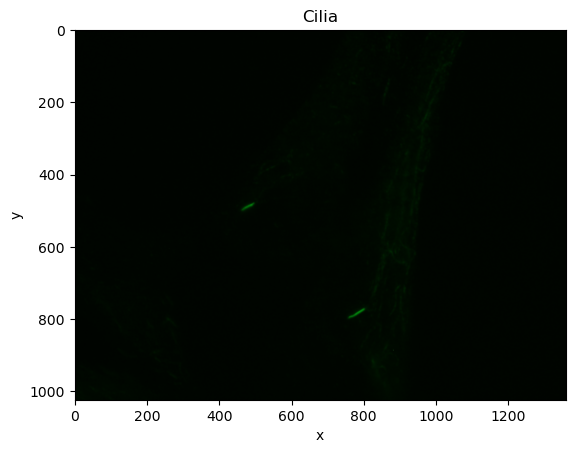

In [2]:
cilia = io.imread("Image_34362.tif")
plt.imshow(cilia)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Cilia')

**Reflect:** Did the displayed colour match your prediction? What does the variable `cilia` contain, and how does that differ from the picture on screen?

The TIFF stores an image as a table of sampled values. Reading it loads that table into memory under the name `cilia`.

**Assignment 1a:** Read the image "Image_34363.tif", call it protein, and display it on screen.

**Predict:** Compared with the cilia image, which colour do you expect to dominate the protein image? Which line of the loading example needs to change?

Text(0.5, 1.0, 'Cilia')

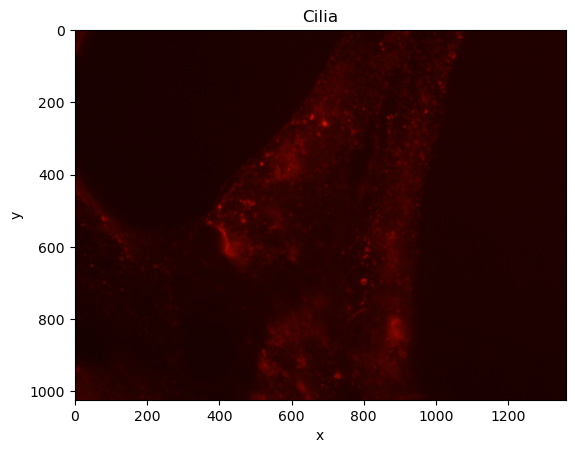

In [3]:
protein = io.imread("Image_34363.tif")
plt.imshow(protein)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Cilia')

**Reflect:** Did the protein image look as you expected? Which change to the loading example selected the new file, and what in the displayed image supports that it is the intended image?

We can probe properties of this table using builtin syntax, for example, if we wish to know what type the image is and how big it is, we can use the print function, which writes stuff to the screen, together with special syntax for various information about the image:

**Predict:** How many axes do you expect the RGB table to have? Will `cilia.size` count pixels or individual channel values?

In [4]:
print('The image is of type', type(cilia))
print('The image has dimensions:', cilia.shape)
print("The total number of values are:", cilia.size)

The image is of type <class 'numpy.ndarray'>
The image has dimensions: (1024, 1360, 3)
The total number of values are: 4177920


**Reflect:** Did the shape and size match your prediction? What does each axis represent, and why are there three times as many stored values as pixels?

The shape is `(1024, 1360, 3)`: rows, columns, and RGB channels. The image has 1024 × 1360 pixels, each with three channel values. The `size` property counts all those individual values.

The elements of the image array can also be printed directly.

**Predict:** Will printing `cilia` show a picture or numbers? How many channel values belong to each pixel?

In [5]:
print("Its values are", cilia)

Its values are [[[ 0  5  0]
  [ 0  4  0]
  [ 0  4  0]
  ...
  [ 0  4  0]
  [ 0  4  0]
  [ 0  5  0]]

 [[ 0  5  0]
  [ 0  4  0]
  [ 0  4  0]
  ...
  [ 0  4  0]
  [ 0  5  0]
  [ 0  5  0]]

 [[ 0  5  0]
  [ 0  5  0]
  [ 0  4  0]
  ...
  [ 0  4  0]
  [ 0  4  0]
  [ 0  4  0]]

 ...

 [[ 0  9  0]
  [ 0 10  0]
  [ 0  9  0]
  ...
  [ 0  6  0]
  [ 0  5  0]
  [ 0  5  1]]

 [[ 0  9  0]
  [ 0 10  0]
  [ 0 10  0]
  ...
  [ 0  5  0]
  [ 0  5  0]
  [ 0  5  0]]

 [[ 0 10  0]
  [ 0 10  0]
  [ 0 10  0]
  ...
  [ 0  5  0]
  [ 0  5  0]
  [ 0  5  0]]]


**Reflect:** How do the brackets group channel values into pixels? What do the first two pixels tell you about the colours at the top-left corner?

The first pixel has RGB values `[0, 5, 0]`, and its neighbour has `[0, 4, 0]`. NumPy abbreviates large arrays with `...`; this does not mean that pixels are missing.

The image values can be read by indexing, e.g., the top left corner of the red, green and blue channels have indices [0,0,0], [0,0,1], [0,0,2] and the neighbouring (along the second dimension) have indices  [0,1,0], [0,1,1], [0,1,2]:

**Predict:** Which indices select the green value at the top-left pixel? Which index changes to select its neighbour along the row?

In [6]:
print("The values of the top corner are (",cilia[0,0,0],",",cilia[0,0,1],",",cilia[0,0,2],")")
print("The values of the neighbour are (",cilia[0,1,0],",",cilia[0,1,1],",",cilia[0,1,2],")")
print("The type of cilia[0,0,0] is",type(cilia[0,0,0]))

The values of the top corner are ( 0 , 5 , 0 )
The values of the neighbour are ( 0 , 4 , 0 )
The type of cilia[0,0,0] is <class 'numpy.uint8'>


**Reflect:** Did the printed values match the pixels in the array output? Which index changes when moving one pixel to the right, and why?

Each channel value has type `uint8`, an unsigned 8-bit integer with values from 0 to 255.

It is typically more practical to access the table-values in groups using slicing. For example, the 3 color values [0,0,0], [0,0,1], [0,0,2] can be access using [0,0,0:3] or equivalently [0,0,:]. For example, the image of all the red values, also known as the the red channel is cilia[:,:,0], and all 3 channels can be shown individually as follows:

**Predict:** Which channel do you expect to show the cilia most clearly? Will selecting one channel give a two-dimensional or three-dimensional array?

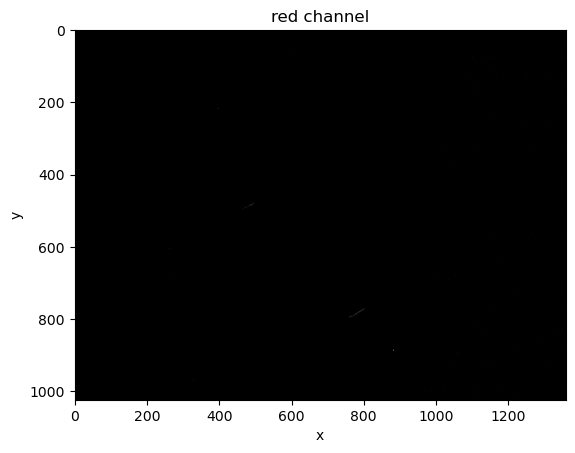

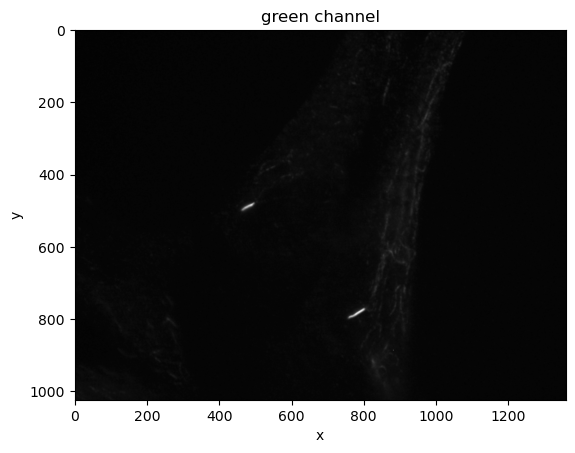

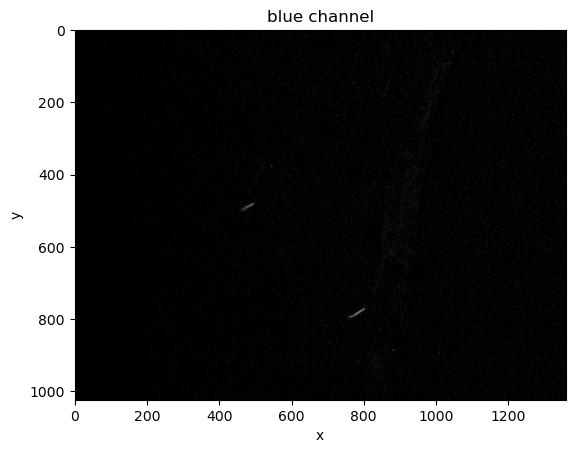

In [7]:
plt.xlabel('x')
plt.ylabel('y')
plt.title('red channel')
plt.imshow(cilia[:,:,0])
plt.show() # Flush the image to screen, since the next 'imshow' is to show a new image
plt.xlabel('x')
plt.ylabel('y')
plt.title('green channel')
plt.imshow(cilia[:,:,1])
plt.show()
plt.xlabel('x')
plt.ylabel('y')
plt.title('blue channel')
plt.imshow(cilia[:,:,2])
plt.show()

**Reflect:** Which channel shows the cilia most clearly, and did that match your prediction? How does the last index in `cilia[:,:,i]` select a channel while keeping all rows and columns?

Above we imshow'ed each channel separately and used plt.show() to force every image to be shown on the screen. The code consists of 3 similar chunks, which often happens in programming. The code is relatively long and difficult to correct. E.g., if we decide that instead of 'x' we want to write 'x (micrometer)', then we must correct the code in many places with the risk of missing a line or adding mistakes. Therefore, it is better to use a loop structure. A common loop is the for-loop, and rewriting the above as a for-loop looks like:

**Predict:** How many figures will `range(3)` produce, and what channel indices will appear in their titles?

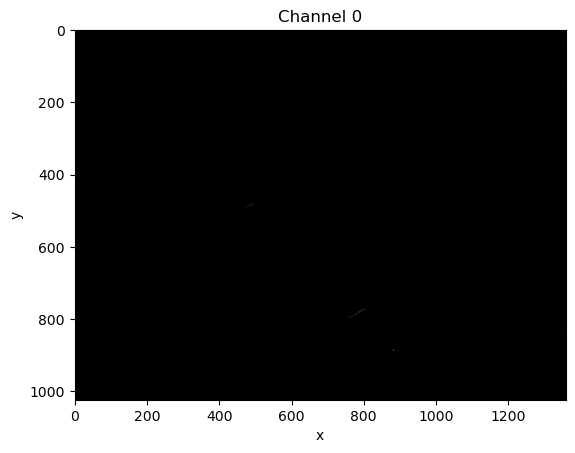

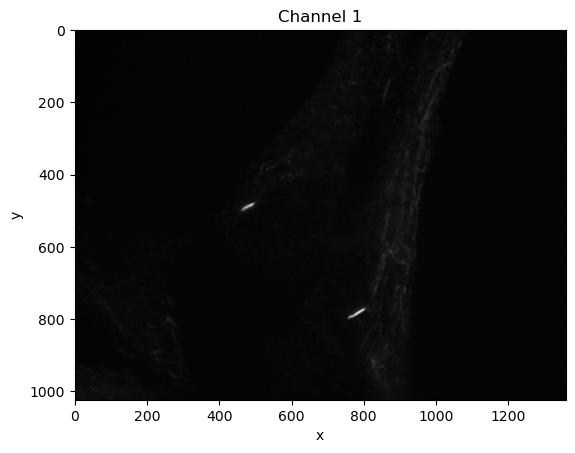

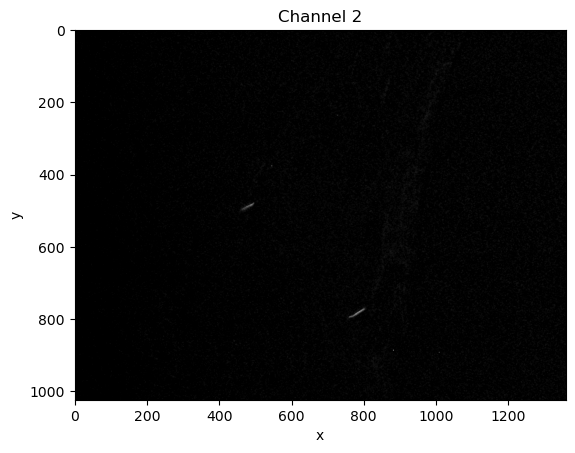

In [8]:
for i in range(3):
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title("Channel " + str(i))
    plt.imshow(cilia[:,:,i])
    plt.show()

**Reflect:** Did the number of figures and their channel indices match your prediction? How does the loop reproduce the three separate displays, and why is it easier to maintain?

Everything indented under `for` repeats, with `i` taking the values 0, 1, and 2. In the title, `str(i)` converts the index to text, and `+` joins the strings. A label written inside the loop applies to each figure.

## 1.1.3 Histograms of images
The image values are the raw data captured in the microscope, and their histogram is a useful initial analysis of the image. E.g., the histogram will tell us if the image is over- or under-saturated if the values cluster near the minimum and maximum possible values, which are 0 and 255 for uint8 types. To see the histogram of the green channel of cilia we write:

**Predict:** From the green-channel image, do you expect more pixels to have low or high intensities?

The image values range from 2 to 142


Text(0.5, 1.0, 'All green values in cilia')

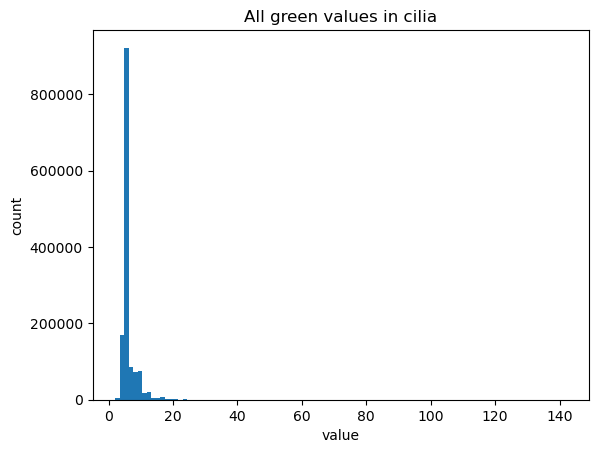

In [9]:
print("The image values range from", cilia[:,:,1].min(), "to", cilia[:,:,1].max())
plt.hist(cilia[:,:,1].flatten(),100)
plt.xlabel('value')
plt.ylabel('count')
plt.title('All green values in cilia')

**Reflect:** Does the histogram support your prediction about low and high intensities? Which part of the histogram supports your interpretation?

The selected green channel is a two-dimensional array. `.flatten()` collects its values into a one-dimensional array, so the histogram counts values from all pixels. The values range from 2 to 142, with most below 20.

**Assignment 1b:** Show histograms of the red and blue channels of cilia so that you can compare them with the green-channel histogram.

**Predict:** Will the red and blue channels have intensity distributions similar to the green channel? What information might be lost if all channels are pooled?

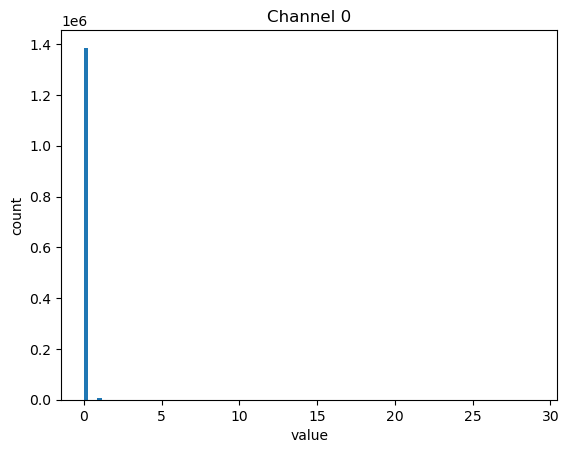

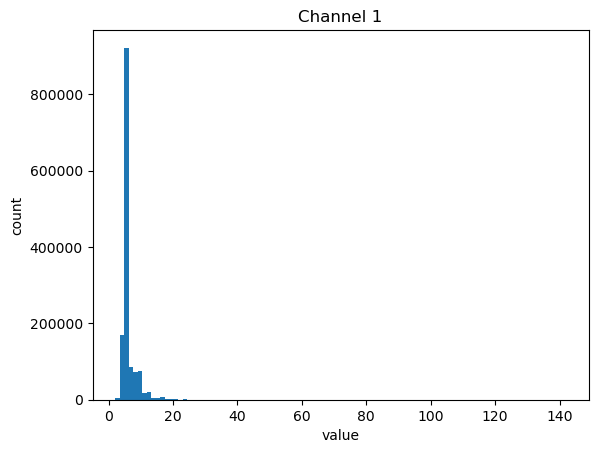

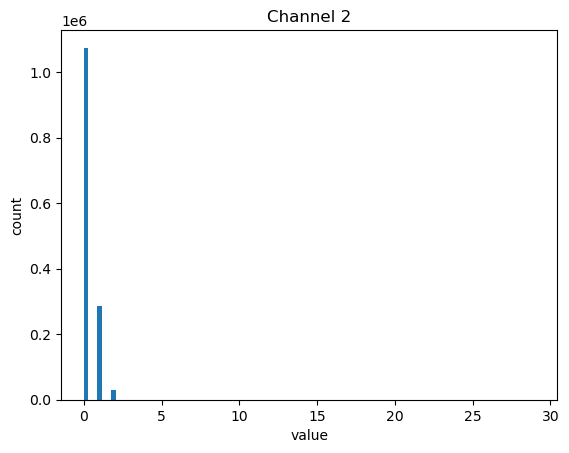

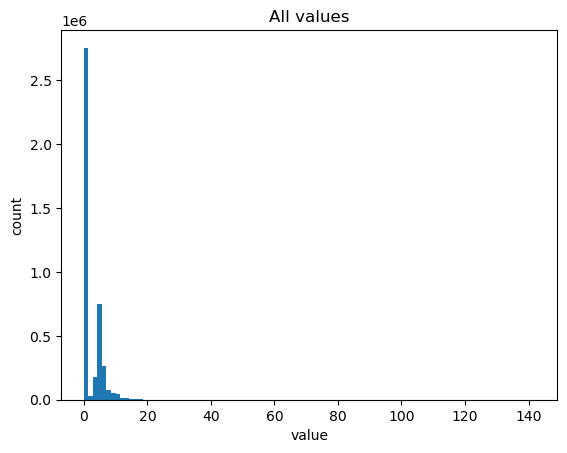

In [10]:
for i in range(3):
    plt.hist(cilia[:,:,i].flatten(),100)
    plt.xlabel('value')
    plt.ylabel('count')
    plt.title("Channel " + str(i))
    plt.show()

# Histogram of all values will summarize the content disregarding color.
plt.hist(cilia.flatten(),100)
plt.xlabel('value')
plt.ylabel('count')
plt.title("All values")
plt.show()

**Reflect:** How do the red- and blue-channel histograms differ from the green-channel histogram? Did those differences match your prediction? In what situation could pooling all channels hide useful information?

**Assignment 1c:** Show a separate histogram for each of the red, green, and blue channels of `protein`, as in the channel examples above. Label each histogram with its channel name or index, and use the same bins and intensity range for all three so that you can compare them. For these uint8 images, use `bins=100, range=(0,255)` in each `plt.hist` call.

**Predict:** Which protein-image channel do you expect to contain the strongest signal? What should its histogram look like compared with the other channels?

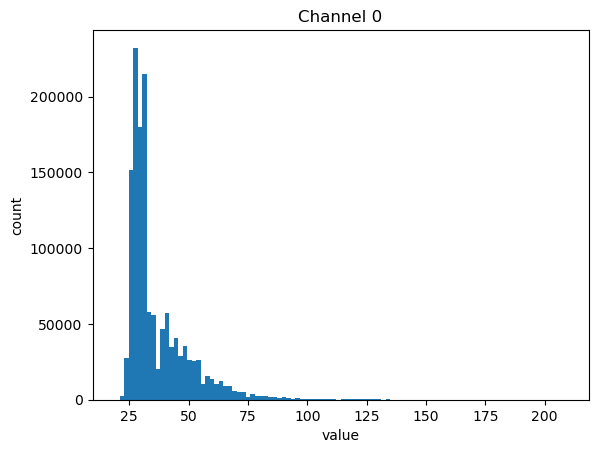

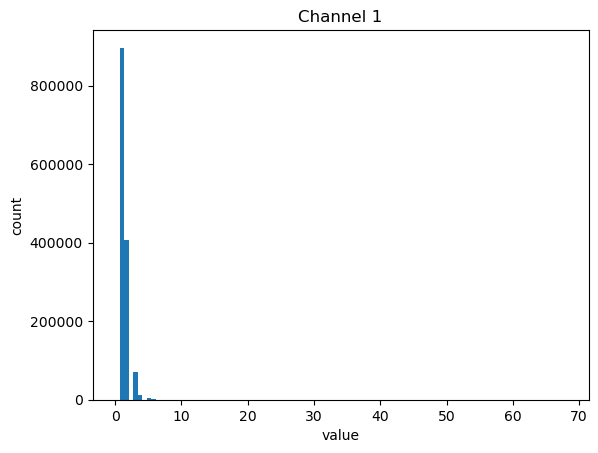

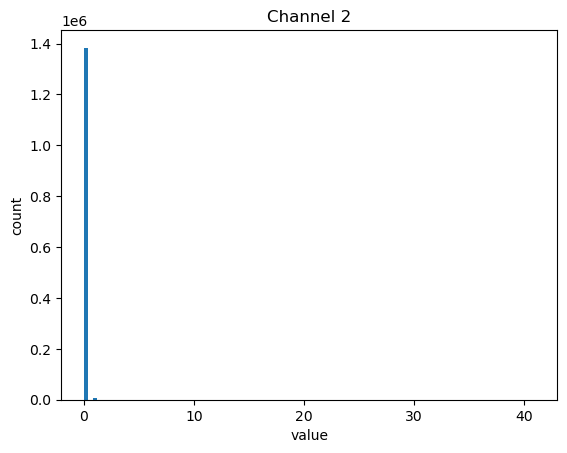

In [11]:
for i in range(3):
    plt.hist(protein[:,:,i].flatten(),100)
    plt.xlabel('value')
    plt.ylabel('count')
    plt.title("Channel " + str(i))
    plt.show()

**Reflect:** Which protein-channel histogram supports using that channel for the protein measurement? Did it match your prediction about the strongest signal? What observations in the three histograms support your choice?

Images often do not use the full range of possible values. The green channel here has values from 2 to 142, within the uint8 range of 0 to 255. If we display it using that full range, it looks relatively dark. We can make a new image by stretching its intensities linearly: subtract the minimum, divide by the original range, and multiply by 255. This maps the lowest value to 0 and the highest to 255. This calculation assumes that the image is not constant, so its maximum is greater than its minimum.

For a two-dimensional grayscale image, `plt.imshow` normally adjusts the display automatically, mapping that image's minimum to black and maximum to white. This is why the earlier green-channel display already showed good contrast. If we display the original and linearly stretched images with automatic limits, they will look essentially the same. To see the effect of stretching, we display both with `vmin=0, vmax=255`. These arguments set the display limits; they do not change the stored pixel values. The stretching calculation creates new values in `stretched` and leaves `cilia` unchanged.

Optional experiment: first run the cell with the fixed limits. Then remove `vmin=0, vmax=255` from both `imshow` calls and rerun it to compare automatic scaling. Restore the fixed limits afterwards.

**Predict:** Which image will look brighter with the fixed display limits, and what will the minimum and maximum of `stretched` be? If you try the optional experiment, how will the two displays compare under automatic scaling?

In [ ]:
green = cilia[:,:,1].astype(float) # Convert before doing arithmetic
print("Original values range from", green.min(), "to", green.max())
stretched = 255.0*(green-green.min())/(green.max()-green.min())
print("Stretched values range from", stretched.min(), "to", stretched.max())

# Use the same display limits for a fair comparison.
plt.imshow(green, vmin=0, vmax=255)
plt.xlabel('column (pixels)')
plt.ylabel('row (pixels)')
plt.title('Original green channel: display range 0 to 255')
plt.show()

plt.imshow(stretched, vmin=0, vmax=255)
plt.xlabel('column (pixels)')
plt.ylabel('row (pixels)')
plt.title('Stretched green channel: display range 0 to 255')
plt.show()

# Compare the stored values using the same histogram bins and range.
plt.hist(green.flatten(), bins=100, range=(0,255), histtype='step', label='Original')
plt.hist(stretched.flatten(), bins=100, range=(0,255), histtype='step', label='Stretched')
plt.xlabel('pixel value')
plt.ylabel('count')
plt.title('Green-channel values before and after stretching')
plt.legend()
plt.show()


**Reflect:** How do the images and histograms compare with your prediction? Which aspects of the image changed, and which stayed the same? Why would automatic display limits make the original and stretched images look essentially the same?

Stretching redistributes intensity values over a wider range without changing the structures or number of pixels. It does not add signal or recover clipped values. The original values remain the basis for quantitative measurements because stretching changes sums, means, and the meaning of numerical thresholds.

When performing arithmetic on a computer, it is very important to understand the types and their limitations. Uint8 stores integers from 0 to 255, with no negative or fractional values. Adding uint8 arrays can overflow: a result above 255 wraps around instead of remaining correct. Convert the image values with `.astype(float)` before doing arithmetic. Converting only after addition, or dividing the sum by `2.0`, cannot undo overflow that has already happened. Floating-point values can represent fractions approximately and have a much wider range. In the stretching example above, we convert the green channel before subtracting and multiplying.

In some cases, it is useful to convert a color image into a gray-value image, e.g., if the color captured is a mixture of red, green, and blue, but we are only interested in how much light there was and not its color components. Python is designed to make such computations simple. For example, to make a new image where each pixel is the sum of red and green pixels, we may write:

**Predict:** Will summing the red and green channels change the number of rows or columns? Can the sum at a pixel be smaller than either nonnegative input value?

In [ ]:
ciliaFloat = cilia.astype(float) # Convert before adding channels
redGreen = ciliaFloat[:,:,0]+ciliaFloat[:,:,1]
plt.xlabel('x')
plt.ylabel('y')
plt.title('sum of red and green')
plt.imshow(redGreen)

**Reflect:** Did the shape and values of `redGreen` match your prediction? How does each output value relate to the two input channels, and why does converting before addition prevent overflow?

**Assignment 1d:** Calculate an image where each pixel is the average of the corresponding values in the three channels, and plot it as a single figure. Print the minimum and maximum across all values in the original image and in the average image. Convert the image to float before adding the channels, as in the example above.

**Predict:** Should the average intensity at a pixel lie between its lowest and highest channel values? What could go wrong if uint8 channels are added before conversion to float?

In [ ]:
ciliaFloat = cilia.astype(float) # Convert before adding channels
avg = (ciliaFloat[:,:,0]+ciliaFloat[:,:,1]+ciliaFloat[:,:,2])/3.0
plt.imshow(avg)
plt.xlabel('x')
plt.ylabel('y')
plt.title('The average image')
plt.show()

for i in range(3):
    print("Channel "+str(i)+" values range from", cilia[:,:,i].min(), "to", cilia[:,:,i].max())

print("The avg values range from", avg.min(), "to", avg.max())

# The min and max of the average image is between min and max of the most extreme channels values as expected

**Reflect:** How do the average image and its minimum and maximum compare with your prediction and with the original image? What does this reveal about averaging channels? Why does conversion to float before addition matter?

# 2 Visual inspection of the amount of protein near the cilia
To visually assess the amount of protein near the cilia, we will make a composite image programmatically. The cilia image is mainly green and the protein image is mainly red. This is lucky because then our composite image can be made by combining the green channel from cilia with the red channel from protein.

**Predict:** What colour should appear where both the cilia and protein signals are strong? Should constructing the composite change `cilia`?

Text(0.5, 1.0, 'composit image')

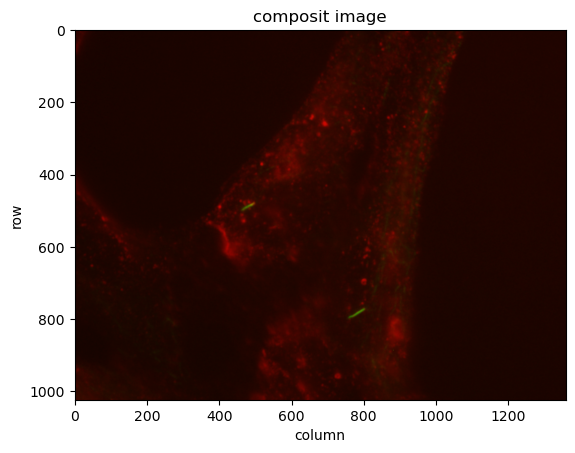

In [15]:
# beware, must use copy otherwise composit changing imCombine would alse change cilia.
# If you want to know more, seek out information on the difference between copy by reference and by value.
composit = cilia.copy() 
composit[:,:,0] = protein[:,:,0]
composit[:,:,2] = 0 # All values in the blue channel are set to zero! 
plt.imshow(composit)
plt.xlabel('column')
plt.ylabel('row')
plt.title('composit image')

**Reflect:** Did coincident red and green signal appear as you predicted? Which image supplies each displayed channel, and why is coincident signal yellow? What does `.copy()` prevent when the channels are replaced?

Alternatively, we could make an average of the two images. This is more complicated since imshow insists on the data being in the range (0,1) for floats or (0,255) for integers. So we stretch the image to the range (0,1).

**Predict:** How does averaging both RGB images differ from taking one channel from each? What range should the normalized values occupy?

In [ ]:
ciliaFloat = cilia.astype(float)
proteinFloat = protein.astype(float)
altComposit = (ciliaFloat+proteinFloat)/2.0
altComposit = (altComposit-altComposit.min())/(altComposit.max()-altComposit.min())
plt.imshow(altComposit)
plt.xlabel('column')
plt.ylabel('row')
plt.title('average composit image')

**Reflect:** How does the average composite differ from the channel-replacement composite? Which channels contribute to it, and why does the floating-point RGB display require normalization? Did its value range match your prediction?

For both composites, we see that there are protein many places and that some coincide with one of the cilium.

The resulting image can be saved to disk. Unfortunately, we have to convert it to a uint8 type first remembering to stretch it from the interval (0,1) to (0,255):

**Predict:** What will happen to the normalized values when they are multiplied by 255? Why is conversion to uint8 done afterwards?

In [17]:
altCompositUint8 = 255.0*altComposit
altCompositUint8 = altCompositUint8.astype(np.uint8)
io.imsave('CombinationOfTwo.tiff',altCompositUint8)

/var/folders/yz/sn2qc9qs7hv31hxnjc_4v9rr0000gn/T/ipykernel_30939/3849815398.py:3: UserWarning: CombinationOfTwo.tiff is a low contrast image
  io.imsave('CombinationOfTwo.tiff',altCompositUint8)


**Reflect:** Did the saved array have the range and data type you predicted? How do multiplication by 255 and conversion to uint8 serve different purposes?

# 3 Programmatical estimation of the amount of protein near the cilia.
In the following, we will estimate the amount of protein near the cilia. The strategy for estimating the amount of protein near the cilia will be 
1. Segment the cilia.
2. Expand the segments slightly.
3. Sum the intensity values in the protein image under the expanded cilia mask.

## 3.1 Segmenting by Thresholding
The cilia are mainly green, and we have seen that by luck this is mostly captured in the green channel. Thus, in the following, we will work with:

**Predict:** Should selecting the green channel again change its intensity range compared with the earlier histogram?

In [18]:
green = cilia[:,:,1]
print('(',green.min(),',',green.max(),')')

( 2 , 142 )


**Reflect:** Did the printed green-channel range agree with the earlier histogram? Why is a single channel useful for this segmentation?

Thresholding is the process of converting an image into a binary or boolean image, where the value 1 or true denotes pixels that belong to the segment and 0 or false denotes pixels that do not. In our case, high values correlate with the location of the cilia and we use the '>' comparison operator (on each pixel):

**Predict:** Will green-channel values of 24, 25, and 26 be True or False in `green > 25`?

segm type: <class 'numpy.ndarray'>
segm size: (1024, 1360)
segm pixel type: <class 'numpy.bool_'>


Text(0.5, 1.0, 'cilia segm')

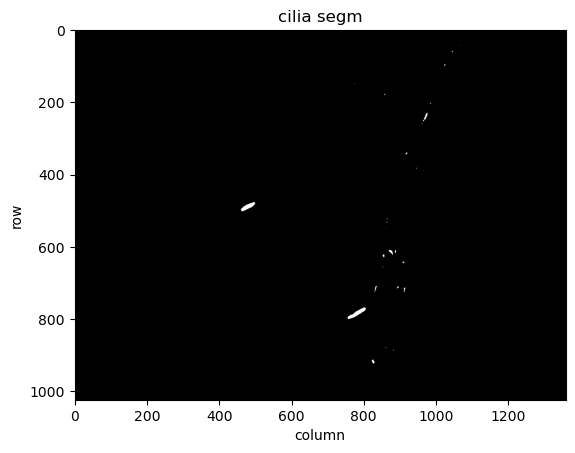

In [19]:
segm = green > 25
print("segm type:", type(segm))
print("segm size:", segm.shape)
print("segm pixel type:", type(segm[0,0]))
plt.imshow(segm)
plt.xlabel('column')
plt.ylabel('row')
plt.title('cilia segm')

**Reflect:** Did intensities 24, 25, and 26 behave as predicted? Why is a value equal to 25 excluded by `green > 25`? How do the bright mask pixels relate to the original image?

The threshold 25 was arbitrarily chosen. Let us compare several thresholds.

**Predict:** As the threshold increases from 25 to 30 to 35, will more or fewer pixels be selected?

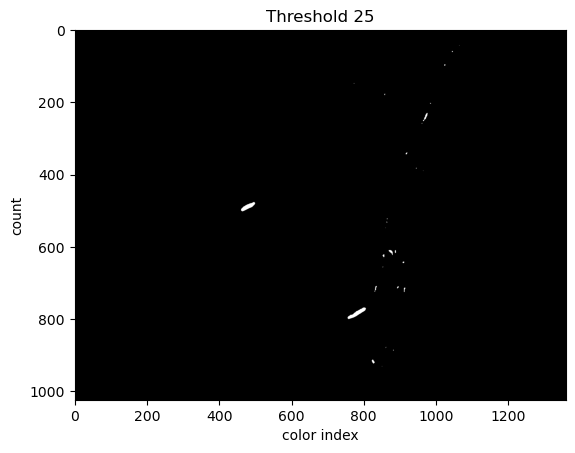

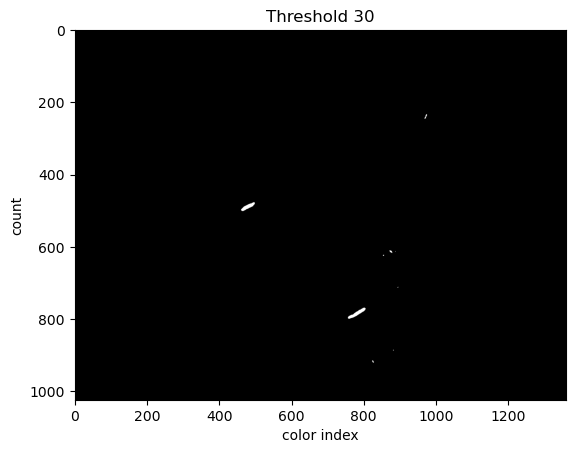

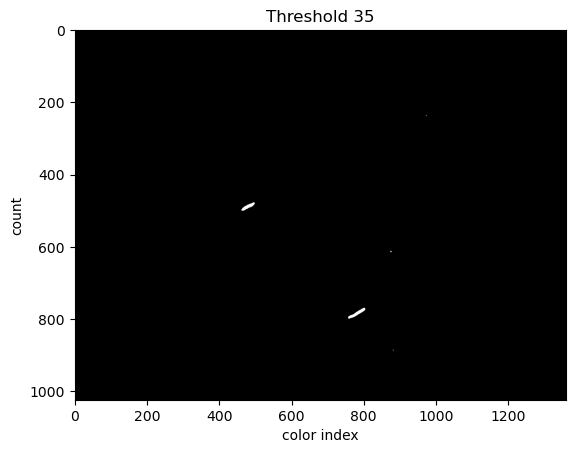

In [20]:
threshold = [25,30,35]
noThresholds = len(threshold)
for i in range(noThresholds):
    segmTest = green > threshold[i]
    plt.imshow(segmTest)
    plt.title("Threshold " + str(threshold[i]))
    plt.xlabel('color index')
    plt.ylabel('count')
    plt.show()

**Reflect:** How do the three masks compare with your prediction? Why can increasing the threshold remove pixels but not add new ones?

**Assignment 1e:** Repeat the above code but experiment with other threshold values. After comparing the results, store your chosen value in `chosenThreshold` and update `segm = green > chosenThreshold`. The following cells use `segm`, so rerun them after changing your choice.

**Predict:** For each threshold you plan to test, predict which dim structures or background pixels might disappear as the threshold increases.

In [ ]:
threshold = [25,50,75,100]
noThresholds = len(threshold)
for i in range(noThresholds):
    segmTest = green > threshold[i]
    plt.imshow(segmTest)
    plt.title("Threshold " + str(threshold[i]))
    plt.xlabel('color index')
    plt.ylabel('count')
    plt.show()

# 75 seems a good balance between getting the cilia without too much noise.
chosenThreshold = 75
segm = green > chosenThreshold

**Reflect:** Looking at the thresholds tested and the chosen mask, how well did your predictions hold? What does the chosen threshold retain or exclude compared with an alternative, and what supports your choice?

## 3.2 Mathematical Morphology
The mask shows where the green pixels are, and we would like to investigate the red pixels in the vicinity of the green. So we use Mathematical Morphology to enlarge the mask slightly. Mathematical morphology has two basic operations: dilation and erosion. Dilation means to expand and erosion the opposite. Technically this is done by interacting the segments with a shape, also known as a structuring element. Here we use the simplest structuring element, a disk of radius 10, and to expand the cilia mask we use dilation:

**Predict:** After dilation, will the number of True pixels decrease, stay the same, or increase? Could two separate segments become connected?

Text(0.5, 1.0, 'Dilated green mask')

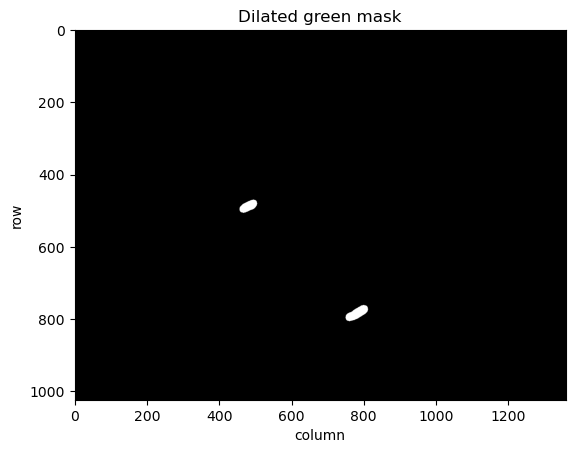

In [22]:
dsk = morphology.disk(10)
msk = morphology.binary_dilation(segm,dsk)
plt.imshow(msk)
plt.xlabel('column')
plt.ylabel('row')
plt.title('Dilated green mask')

**Reflect:** Did dilation affect mask area and connectivity as you predicted? Which regions were added, and why are the original segments still included?

A radius-10 disk expands the segments approximately 10 pixels outward. An isolated segment away from the image boundary can therefore become approximately 20 pixels wider, with 10 pixels added on each side. Nearby segments may merge, and expansion is clipped at the image boundary. The mask includes the original segments and their expanded surroundings.

**Assignment 1f:** Make a for-loop that tests different disk-radii and choose one that you think will work well for combining it with the protein image. Use a temporary mask such as `mskTest` inside the loop. After comparing the results, store your chosen radius in `chosenRadius`, then create `dsk = morphology.disk(chosenRadius)` and `msk = morphology.binary_dilation(segm, dsk)`. The following cells use `msk`, so rerun them after changing your choice.

**Predict:** How will increasing the disk radius affect mask area and the chance of including unrelated protein signal?

In [ ]:
radii = [5,10,20]
for radius in radii:
    dskTest = morphology.disk(radius)
    mskTest = morphology.binary_dilation(segm,dskTest)
    plt.imshow(mskTest)
    plt.xlabel('column')
    plt.ylabel('row')
    plt.title('Dilated green mask r='+str(radius))
    plt.show()

# Choose explicitly rather than using the last mask from the loop.
chosenRadius = 20
dsk = morphology.disk(chosenRadius)
msk = morphology.binary_dilation(segm,dsk)


**Reflect:** How do the tested radii and resulting masks compare with your prediction? What tradeoff between covering the cilia neighbourhood and including unrelated signal supports your chosen radius?

## 3.3 Summing in the protein image
The protein image is mainly red, and by luck this is captured mainly in the red channel. So, in the following, we will use:

**Predict:** Which channel index selects the red signal? Should selecting that channel change the stored values?

In [24]:
red = protein[:,:,0]
print('(',red.min(),',',red.max(),')')

( 19 , 209 )


**Reflect:** Did selecting the red channel preserve the values as predicted? What does its range tell you, and why is this channel used for the protein measurement?

The mask can be used to select pixels in the protien image by multiplication.

**Predict:** What will multiplication do to a red-channel pixel where `msk` is False? What will happen where it is True?

Text(0.5, 1.0, 'redMsk segm')

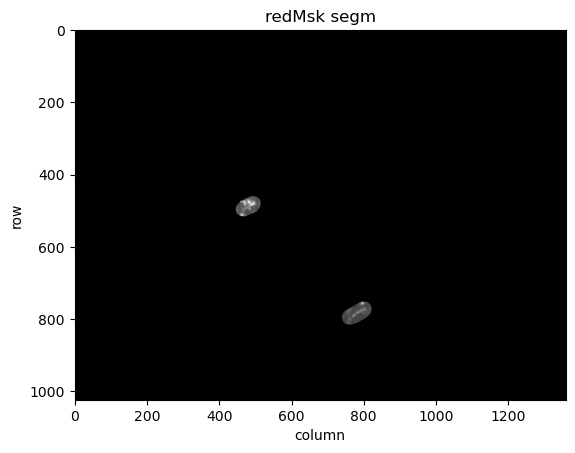

In [25]:
redMsk = red*msk
plt.imshow(redMsk)
plt.xlabel('column')
plt.ylabel('row')
plt.title('redMsk segm')

**Reflect:** How does `redMsk` compare with `red` and with your prediction? Why are pixels outside the mask zero while those inside retain their original intensities?

We see that one cilium has more protein in its vicinity than the other. In this module, we are only interested in summary statistics, so we sum the pixel values in the protein image and compare this with the number of pixels in the mask image.

**Predict:** Which pixels should contribute to the denominator when calculating the mean intensity inside the mask? How would including all image pixels affect that mean?

In [26]:
print("Sum of redMsk:",redMsk.sum())
print("Area of msk:",msk.sum())
print("Average value:", redMsk.sum()/msk.sum())

Sum of redMsk: 347596
Area of msk: 6240
Average value: 55.70448717948718


**Reflect:** How does the reported average relate to your prediction? Why does `msk.sum()` count selected pixels, and why is `redMsk.sum()/msk.sum()` the mean inside the mask rather than over the entire image?

**Assignment 1g:** Assume that we are interested in the number of high values in the protein image near the cilia, make a program, which chooses a suitable threshold for the protein image and count the number of pixels that are both high in protein and near the cilia.

**Optional hint:** A comparison such as `image > threshold` creates a Boolean mask. Combine two Boolean masks with `maskA & maskB`: a pixel is `True` only where both masks are `True`. Use `&` rather than Python's `and` for arrays. If you write comparisons directly, put each comparison in parentheses, for example `(imageA > thresholdA) & (imageB > thresholdB)`. Remember that summing a Boolean mask counts its `True` pixels.

**Predict:** Can the count exceed the number of pixels in the cilia mask? What will happen to the count if you raise the protein threshold while keeping that mask fixed?

( 19 , 209 )


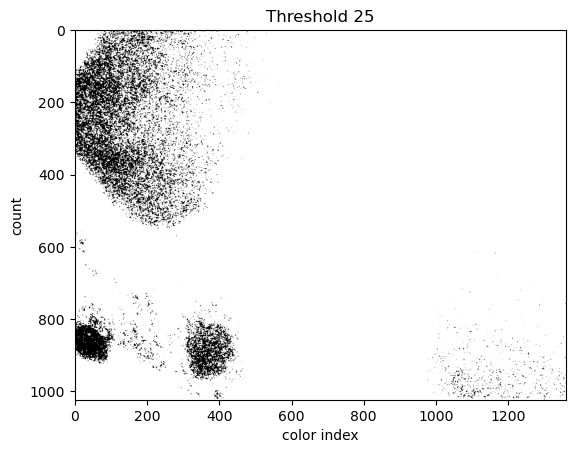

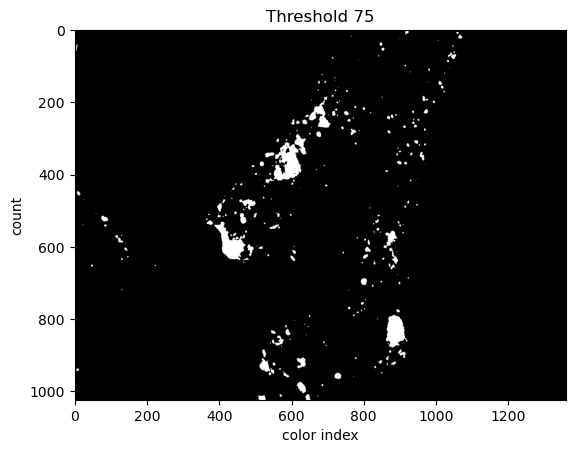

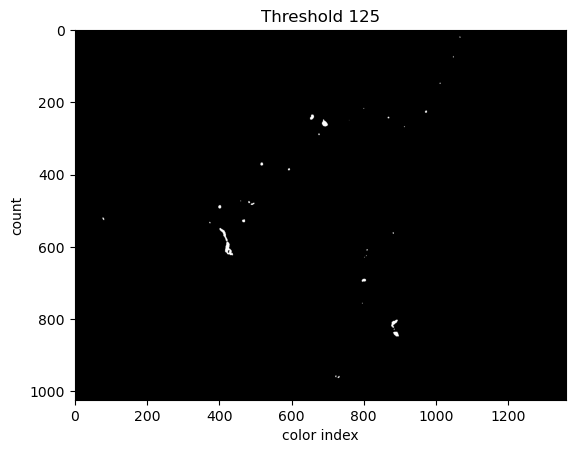

In [27]:
red = protein[:,:,0]
print('(',red.min(),',',red.max(),')')

threshold = [25,75,125]
noThresholds = len(threshold)
for i in range(noThresholds):
    segmTest = red > threshold[i]
    plt.imshow(segmTest)
    plt.title("Threshold " + str(threshold[i]))
    plt.xlabel('color index')
    plt.ylabel('count')
    plt.show()

# 75 seems a good balance between getting the protein without too much noise.
segmRed = red > 75

Text(0.5, 1.0, 'segmRedMsk segm')

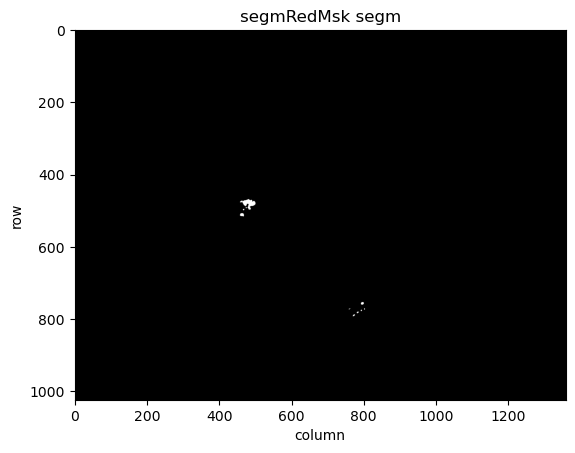

In [28]:
segmRedMsk = segmRed*msk
plt.imshow(segmRedMsk)
plt.xlabel('column')
plt.ylabel('row')
plt.title('segmRedMsk segm')

In [29]:
print("Sum of redMsk:",segmRedMsk.sum())
print("Area of msk:",msk.sum())
print("Average value:", segmRedMsk.sum()/msk.sum())

Sum of redMsk: 794
Area of msk: 6240
Average value: 0.12724358974358974


**Reflect:** How does the count of high-protein pixels relate to the total mask area and your prediction? What two conditions does each counted pixel satisfy? What did the comparison of protein thresholds reveal when the cilia mask was kept fixed?

## 3.4 User-defined functions
We have used functions such as `print`, `plt.imshow`, and `morphology.disk`. We can also define our own functions to give a name to a sequence of steps and reuse it with different inputs. This is useful when we want to repeat the segmentation, dilation, and intensity measurements from sections 3.1–3.3 without copying all the code each time.

A function has a name, inputs called **parameters**, an indented body of code, and optionally a result sent back with **return**. Here is a small example:

Run the cell containing a function definition before calling it. If you edit its body, rerun the definition cell before trying the updated function.

**Predict:** What will the two calls below print? Will defining the function by itself print a result?

In [ ]:
def double_value(value):
    doubled = 2 * value
    return doubled

first_result = double_value(3)
second_result = double_value(5)
print(first_result)
print(second_result)


**Reflect:** Did the two function calls give the results you predicted? Why can the same function produce different values, and which line sends each result back?

`def double_value(value):` defines the function. Its indented body runs when it is called. In `double_value(3)`, the argument `3` becomes the parameter `value`. Variables created in the body are local to that call. `return doubled` sends the result back to the caller, where it can be stored for later calculations; printing only displays it.

A function can return several results separated by commas. For example, `return total, area, average` sends back three values together. Assign them separate names with `total, area, average = function_name(...)`, in the same order.

**Assignment 1h:** Encapsulate the steps from sections 3.1–3.3 in a function named `measure_near_cilia(green_image, red_image, threshold, radius)`. The two image inputs should be the two-dimensional green and red channels, with the same shape.

1. Segment `green_image` using the supplied `threshold`.
2. Dilate that segmentation using a disk with the supplied `radius`.
3. Use the expanded mask to select intensities from `red_image`. Calculate the intensity sum, the mask area in pixels, and the mean intensity inside the mask, as in section 3.3.
4. Return the three measurements in this order: intensity sum, mask area, mean intensity.

Copy the relevant lines from sections 3.1–3.3 and modify them to use the function parameters. Use the image and parameter inputs rather than the existing global variables `green`, `red`, `segm`, or `msk`. Keep plotting and printing outside the function so that it can be reused for calculations.

Call your function with `green`, `red`, `chosenThreshold`, and `chosenRadius`. Store the three returned measurements in separate variables and print them. Compare them with section 3.3 after rerunning that section with the same threshold and radius. Then call the function again with a different radius while keeping the other inputs fixed.

**Predict:** Will the first function call reproduce section 3.3 with the same inputs? If you increase only the radius, what should happen to mask area and intensity sum? Does the mean intensity necessarily increase too?

In [ ]:
def measure_near_cilia(green_image, red_image, threshold, radius):
    segmentation = green_image > threshold
    disk = morphology.disk(radius)
    mask = morphology.binary_dilation(segmentation, disk)
    masked_red = red_image * mask
    total = masked_red.sum()
    area = mask.sum()
    # Optional extension: the mean is undefined for an empty mask.
    if area == 0:
        average = np.nan
    else:
        average = total / area
    return total, area, average


total, area, average = measure_near_cilia(green, red, chosenThreshold, chosenRadius)
print('Threshold:', chosenThreshold, 'Radius:', chosenRadius)
print('Intensity sum:', total)
print('Mask area:', area)
print('Mean intensity:', average)

# Reproduce section 3.3 with the same explicitly chosen parameters.
reference_segm = green > chosenThreshold
reference_mask = morphology.binary_dilation(reference_segm, morphology.disk(chosenRadius))
reference_red = red * reference_mask
print('Section 3.3 intensity sum:', reference_red.sum())
print('Section 3.3 mask area:', reference_mask.sum())
if reference_mask.sum() == 0:
    reference_average = np.nan
else:
    reference_average = reference_red.sum() / reference_mask.sum()
print('Section 3.3 mean intensity:', reference_average)

larger_radius = chosenRadius + 5
larger_total, larger_area, larger_average = measure_near_cilia(
    green, red, chosenThreshold, larger_radius
)
print('Threshold:', chosenThreshold, 'Radius:', larger_radius)
print('Intensity sum:', larger_total)
print('Mask area:', larger_area)
print('Mean intensity:', larger_average)


**Reflect:** Did the first call reproduce section 3.3 with the same threshold and radius? What might account for any difference? How did the measurements from the two calls compare with your predictions about radius, sum, area, and mean? What does this example suggest about the value of a reusable function?